<a href="https://colab.research.google.com/github/AnishaAB26/Ml/blob/main/Spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files

uploaded = files.upload()

Saving SMSSpamCollection to SMSSpamCollection (1)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["Category", "Message"]
)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
print(df["Category"].value_counts())

Dataset Shape: (5572, 2)

Column Names:
Index(['Category', 'Message'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
Category    0
Message     0
dtype: int64

Category Distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64


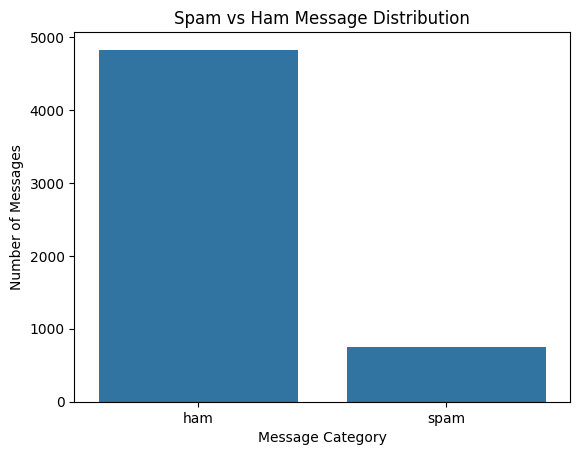

In [7]:
sns.countplot(x="Category", data=df)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

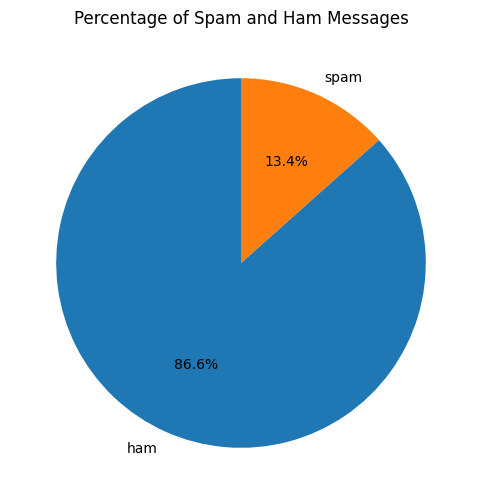

In [8]:
category_count = df["Category"].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    category_count,
    labels=category_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Spam and Ham Messages")
plt.show()

In [9]:
df["Category"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

print(df.head())

   Category                                            Message
0         0  Go until jurong point, crazy.. Available only ...
1         0                      Ok lar... Joking wif u oni...
2         1  Free entry in 2 a wkly comp to win FA Cup fina...
3         0  U dun say so early hor... U c already then say...
4         0  Nah I don't think he goes to usf, he lives aro...


In [10]:
X = df["Message"]
y = df["Category"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: Message, dtype: object

Target:
0    0
1    0
2    1
3    0
4    0
Name: Category, dtype: int64


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [12]:
knn_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english"
    )),
    ("knn", KNeighborsClassifier(
        metric="cosine",
        algorithm="brute"
    ))
])

print("KNN Pipeline Created Successfully!")

KNN Pipeline Created Successfully!


In [14]:
k_values = list(range(1, 22, 2))

param_grid = {
    "knn__n_neighbors": k_values,
    "knn__weights": ["uniform", "distance"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

print(
    "Best Cross Validation F1 Score:",
    grid_search.best_score_
)

Best Parameters: {'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Best Cross Validation F1 Score: 0.9362564828695236


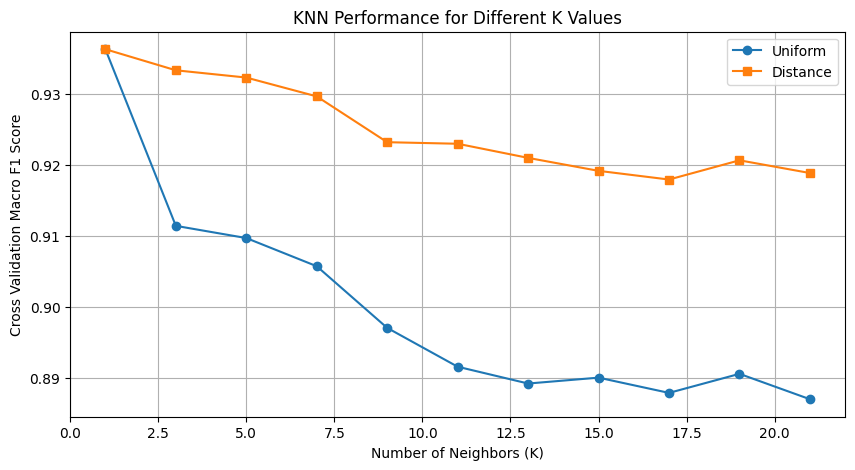

In [15]:
results = pd.DataFrame(grid_search.cv_results_)

uniform_results = results[
    results["param_knn__weights"] == "uniform"
]

distance_results = results[
    results["param_knn__weights"] == "distance"
]

plt.figure(figsize=(10, 5))

plt.plot(
    uniform_results["param_knn__n_neighbors"].astype(int),
    uniform_results["mean_test_score"],
    marker="o",
    label="Uniform"
)

plt.plot(
    distance_results["param_knn__n_neighbors"].astype(int),
    distance_results["mean_test_score"],
    marker="s",
    label="Distance"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross Validation Macro F1 Score")
plt.title("KNN Performance for Different K Values")

plt.legend()
plt.grid()
plt.show()

In [16]:
best_model = grid_search.best_estimator_

print("Final KNN Model:")
print(best_model)

Final KNN Model:
Pipeline(steps=[('tfidf', TfidfVectorizer(stop_words='english')),
                ('knn',
                 KNeighborsClassifier(algorithm='brute', metric='cosine',
                                      n_neighbors=1))])


In [17]:
y_pred = best_model.predict(X_test)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 1 0 0 0 0 0 0]

Predicted Values:
[0 0 0 1 0 0 0 0 0 0]


In [18]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("MODEL PERFORMANCE")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))

MODEL PERFORMANCE
Accuracy: 95.61 %
Precision: 0.868
Recall: 0.792
F1 Score: 0.828


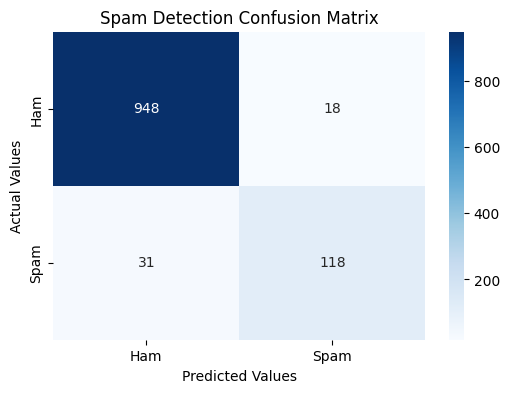

              precision    recall  f1-score   support

         Ham       0.97      0.98      0.97       966
        Spam       0.87      0.79      0.83       149

    accuracy                           0.96      1115
   macro avg       0.92      0.89      0.90      1115
weighted avg       0.95      0.96      0.96      1115



In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Spam Detection Confusion Matrix")

plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

In [22]:
message = input("Enter an SMS message: ")

prediction = best_model.predict([message])

print("\nPrediction:")

if prediction[0] == 1:
    print("SPAM MESSAGE")
else:
    print("HAM (NORMAL MESSAGE)")

Enter an SMS message: Free entry in 2 a wkly comp to win FA Cup fina..

Prediction:
SPAM MESSAGE
